# Программирование на языке Python 
# Неделя 6. Pandas

[Документация pandas](https://pandas.pydata.org/docs/)

Данные для семинара:

*   [Restaurant Reviews](https://www.kaggle.com/datasets/joebeachcapital/restaurant-reviews) - с ним будем работать в первую очередь

Датасет можно скачать [вот тут](https://drive.google.com/drive/folders/1Gb_QnXUSBOQpcqovj-KY7YfduxUzZbQD?usp=drive_link), если не хочется входить в аккаунт кеггла. ([Тут](https://www.kaggle.com/discussions/general/74235) есть инструкция-обсуждение о том, как соединить Kaggle и Colab.)


In [1]:
import pandas as pd

Основная сущность, с которой работает библиотека - это датафрейм или таблица (`DataFrame`). Каждый датафрейм состоит из столбцов типа `Series` (одномерных массивов, которые могут хранить значения любого типа данных).

Датафрейм можно получить различными способами, но основных два:

- создать из словаря или списка

In [41]:
dct = {
    'age': [12, 5, 15, 25],
    'height': [140, 110, 165, 180]
}
pd.DataFrame(dct)

,age,height
0,12,140
1,5,110
2,15,165
3,25,180


In [42]:
lst = [
    [12, 140],
    [5, 110],
    [15, 165],
    [25, 180]
]
pd.DataFrame(lst, columns=['age', 'height'])

,age,height
0,12,140
1,5,110
2,15,165
3,25,180


- загрузить из файла (csv, tsv, excel etc.)
    - **CSV**. Используется функция `read_csv()`. Аргумент `file` является строкой, в которой записан путь до файла с дата-сетом. Для записи данных из `DataFrame` в CSV-файл используется метод `to_csv(file)`.
    - **Excel**. Используется функция `read_excel()`. Для записи данных из `DataFrame` в Excel-файл используется метод `to_excel()`.
    - **JSON**. Используется функция `read_json()`. Для записи данных из DataFrame в JSON используется метод `to_json()`.
    - **Онлайн-таблицы** (на страницах сайта). Используется функция `read_html()`.


In [72]:
df = pd.read_csv("Restaurant reviews.csv")

У таблицы есть строки и столбцы. Посмотрим, как выглядит таблица (по умолчанию head вводит 5 строк):

In [5]:
df.head(2)

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,7514
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0,2447.0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0,NaN


Можно смотреть не верхние строки, а случайные или нижние:

In [6]:
df.sample(2)

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,7514
270,Flechazo,Lavanya,"The service is excellent ,special thanks for r...",5,1 Review,4/27/2019 13:35,0,NaN
9448,Dunkin' Donuts,Kiran Ramoju,good taste.loved it,5,"6 Reviews , 3 Followers",5/6/2018 20:17,0,NaN


In [7]:
df.tail(2)

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,7514
9998,Chinese Pavilion,Nayana Shanbhag,I personally love and prefer Chinese Food. Had...,4,"13 Reviews , 144 Followers",5/31/2016 17:22,0,NaN
9999,Chinese Pavilion,Bhargava Krishna,Checked in here to try some delicious chinese ...,3.5,"472 Reviews , 1302 Followers",5/31/2016 16:41,6,NaN


Можно узнать размер таблицы:

In [8]:
df.shape # это кортеж, можно взять элемент по индексу

(10000, 8)

Можно взять набор столбцов таблицы:

In [9]:
df.columns

Index(['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time',
       'Pictures', '7514'],
      dtype='str')

Попробуем выбрать столбец датафрейма.

In [10]:
df['Reviewer'].head(3)

# или вот так, но работает только с названиями, соответсвующими требованиям к
# названиям атрибутов
# df.Reviewer.head(3)

0       Rusha Chakraborty
1    Anusha Tirumalaneedi
2         Ashok Shekhawat
Name: Reviewer, dtype: str

In [11]:
df[['Reviewer', 'Review', 'Rating']].head(3)

,Reviewer,Review,Rating
0,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5
1,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5
2,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5


Еще столбец можно взять с помощью метода `.loc`, но про него ниже вместе со строками.

Попробуем выбрать строку датафрейма.

In [17]:
df.iloc[10]  # именно 10-я стhока таблицы

Restaurant                                      Beyond Flavours
Reviewer                                       Saubhagya Bhuyan
Review        The service was great and the food was awesome...
Rating                                                        5
Metadata                                  1 Review , 1 Follower
Time                                            5/22/2019 22:22
Pictures                                                      0
7514                                                        NaN
Name: 10, dtype: object

In [18]:
df.loc[10]  # строка таблицы с индексом 10

Restaurant                                      Beyond Flavours
Reviewer                                       Saubhagya Bhuyan
Review        The service was great and the food was awesome...
Rating                                                        5
Metadata                                  1 Review , 1 Follower
Time                                            5/22/2019 22:22
Pictures                                                      0
7514                                                        NaN
Name: 10, dtype: object

Казалось, бы `loc` и `iloc` очень похожи, однако если iloc работает именно с целым числом - номером строки (есть еще нюансы, но про них лучше в документации почитать), то loc - с индексом строки, который в общем случае может быть и строковым типом и даже числом с плавающей точкой или логической переменной.

In [23]:
df_with_idx = pd.DataFrame({
    "name": ["Алиса", "Боб", "Чарли", "Даша"],
    "age": [25, 30, 35, 40],
}, index=["a", "b", "c", "d"])
df_with_idx

,name,age
a,Алиса,25
b,Боб,30
c,Чарли,35
d,Даша,40


In [24]:
df_with_idx.loc["a"]

name    Алиса
age        25
Name: a, dtype: object

А еще с помощью `loc` можно вот так:

In [ ]:
df.loc[5:10, 'Restaurant':'Metadata']

,Rating,Metadata
5,5,1 Review
6,5,1 Review
7,4,1 Review
8,5,"1 Review , 1 Follower"
9,5,"1 Review , 1 Follower"
10,5,"1 Review , 1 Follower"


И даже вот так:

In [55]:
df.loc[df.Restaurant == 'Beyond Flavours',
 ['Restaurant', 'Rating', 'Metadata']].head(3)

,Restaurant,Rating,Metadata
0,Beyond Flavours,5,"1 Review , 2 Followers"
1,Beyond Flavours,5,"3 Reviews , 2 Followers"
2,Beyond Flavours,5,"2 Reviews , 3 Followers"


С помощью одного метода мы смогли вытощить нужные нам строки и столбцы. И здесь видно еще одно отличие `loc` и `iloc`: в первом случае обе границы диапазона будут включены при срезе. А с `iloc` - нет, там все как у списков:

In [56]:
df.iloc[5:10]

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,7514
5,Beyond Flavours,Nagabhavani K,"Ambiance is good, service is good, food is aPr...",5,1 Review,5/24/2019 15:22,0,NaN
6,Beyond Flavours,Jamuna Bhuwalka,"Its a very nice place, ambience is different, ...",5,1 Review,5/24/2019 1:02,0,NaN
7,Beyond Flavours,Sandhya S,Well after reading so many reviews finally vis...,4,1 Review,5/23/2019 15:01,0,NaN
8,Beyond Flavours,Akash Thorat,"Excellent food , specially if you like spicy f...",5,"1 Review , 1 Follower",5/22/2019 23:12,0,NaN
9,Beyond Flavours,Smarak Patnaik,Came for the birthday treat of a close friend....,5,"1 Review , 1 Follower",5/22/2019 22:37,0,NaN


В целом, логика фильтрации в пандасе достаточно мощная, хотя и "многословная". Например, мы можем выделить отзывы о B-Dubs или Paradise, которые дали люди с именем на N.

In [28]:
df[df.Restaurant.isin(['B-Dubs', 'Paradise']) & df["Reviewer"].str.startswith('N')]

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,7514
132,Paradise,Nitesh,Awesome biryani and kebabs. Apollo fish is the...,5,0 Reviews,5/22/2019 22:55,0,NaN
140,Paradise,Noor Mohammed Zubair,Taste: there was huge hype about biryani hence...,3,"45 Reviews , 48 Followers",5/22/2019 12:46,0,NaN
168,Paradise,Nikhil Reddy,Gud food..fast service.. best people in the re...,4,"1 Review , 1 Follower",5/15/2019 20:22,0,NaN
191,Paradise,N Bharath Kumar Goud,Paradise is one my favourite restaurants to ea...,4,1 Review,5/11/2019 17:31,0,NaN
2214,B-Dubs,Nikhil Raj,Was my first visit and it was awesome experien...,5,"1 Review , 2 Followers",5/14/2019 23:39,0,NaN
2224,B-Dubs,Nrusimha Akundy,Polite and friendly and service is awesome and...,5,"1 Review , 14 Followers",5/8/2019 23:28,0,NaN
2232,B-Dubs,NAGUBANDI ANOOP 14BEC0308,The party was great...the food was awesome and...,5,1 Review,5/8/2019 22:51,0,NaN
2266,B-Dubs,Nishanth Bhan,Fantastic place to watch ipl. Great wings. Fan...,5,"1 Review , 16 Followers",4/21/2019 22:11,1,NaN


Для связи отдельных условий могут использоваться `&` (и), `|` (или), `^` (либо) или `~` (не)

Колонки и строки можно добавлять и удалять достаточно легко. Вот у нас есть какая-то странная колонка 7514 — явно ошибка в данных. Удалим ее:

In [29]:
df = df.drop("7514", axis="columns")  # axis=1 / axis="columns" отвечает за столбцы

# или вот так
# df = df.drop(columns=['7514'])

df.head(2)

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0


Теперь давайте добавим колонку, в которой будет True, если картинок больше нуля, и False - если меньше.

In [59]:
df['Pics_exist'] = df.Pictures > 0
df.head(2)

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,Pics_exist
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0,False
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0,False


Еще мы можем получать всякую статистику по нашим данным.
- Как часто встречаются разные рестораны (датасет идеален с этой точки зрения, всех ресторанов поровну)?


In [30]:
df.Restaurant.value_counts()

# или так, что более универсально, так как можно по нескольким колонкам считать
# df.value_counts('Restaurant')

Restaurant
Beyond Flavours                    100
Paradise                           100
Flechazo                           100
Shah Ghouse Hotel & Restaurant     100
Over The Moon Brew Company         100
                                  ... 
Desi Bytes                         100
Hyderabadi Daawat                  100
Zega - Sheraton Hyderabad Hotel    100
Triptify                           100
Chinese Pavilion                   100
Name: count, Length: 100, dtype: int64

- Нет ли у нас пропущенных значений в колонках?

In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Restaurant  10000 non-null  str  
 1   Reviewer    9962 non-null   str  
 2   Review      9955 non-null   str  
 3   Rating      9962 non-null   str  
 4   Metadata    9962 non-null   str  
 5   Time        9962 non-null   str  
 6   Pictures    10000 non-null  int64
dtypes: int64(1), str(6)
memory usage: 3.8 MB


Есть, но немного. Если они нам мешают, то их можно удалить:

In [32]:
df = df.dropna()
# у dropna() есть аргумент how, которому можно, например, сообщать значение all,
# если мы хотим удалять только совсем пустые
df.info()

<class 'pandas.DataFrame'>
Index: 9955 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Restaurant  9955 non-null   str  
 1   Reviewer    9955 non-null   str  
 2   Review      9955 non-null   str  
 3   Rating      9955 non-null   str  
 4   Metadata    9955 non-null   str  
 5   Time        9955 non-null   str  
 6   Pictures    9955 non-null   int64
dtypes: int64(1), str(6)
memory usage: 3.9 MB


Выше можно увидеть, что у колонок бывают разные типы. Самый общий - это тип `object`, с ним не работает никакая математика, чаще всего он содержит строки или какие-то пользовательские объекты.

Заметим, что колонка Rating почему-то тоже `object`, хотя должна быть `int64`, как Pictures. Попробуем это поправить:

In [33]:
df["Rating"] = pd.to_numeric(df["Rating"])

ValueError: Unable to parse string "Like" at position 7597

Упало :(

Попробуем посмотреть, что там вообoе встречается:

In [34]:
df["Rating"].unique()

<ArrowStringArray>
['5', '4', '1', '3', '2', '3.5', '4.5', '2.5', '1.5', 'Like']
Length: 10, dtype: str

Много всякой ерунды и все строковый тип данных. Давайте напишем функцию, которая поможет нам с этим справиться, и применим ее к столбцу:

In [36]:
def rating_to_num(rating):
  if rating == "Like":
    return 5
  else:
    return round(float(rating))

# или то же самое лямбдой
# df["Rating"].apply(lambda rating: 5 if rating == "Like" else round(float(rating)))

df["Rating"] = df["Rating"].apply(rating_to_num)
df["Rating"].value_counts()

Rating
5    3827
4    2489
1    1735
3    1192
2     712
Name: count, dtype: int64

Теперь мы можем посмотреть всякие статистики по столбцу с рейтингом:

In [66]:
df.describe()

,Rating,Pictures
count,9955.000000,9955.000000
mean,3.598795,0.751984
std,1.482589,2.575691
min,1.000000,0.000000
25%,3.000000,0.000000
50%,4.000000,0.000000
75%,5.000000,0.000000
max,5.000000,64.000000


И порисовать графики:

<Axes: ylabel='Frequency'>

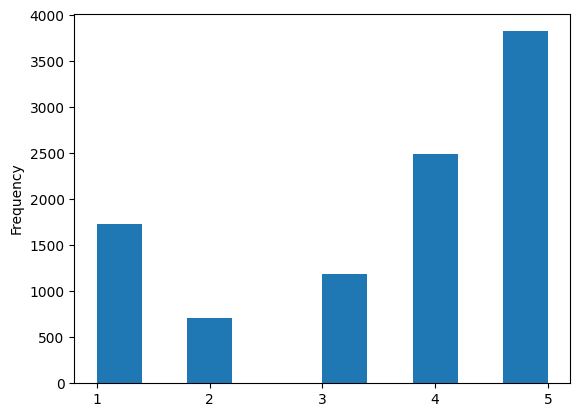

In [37]:
df["Rating"].plot(kind="hist", xticks=[1, 2, 3, 4, 5])

Но сейчас мы все замеряем по всем ресторанам в целом. Давайте сгруппируем по названию ресторана:

In [38]:
df.groupby(by = "Restaurant").head()

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0
...,...,...,...,...,...,...,...
9900,Chinese Pavilion,Khan,Starting off with food...They have amazing and...,5,1 Review,5/13/2019 12:05,0
9901,Chinese Pavilion,Diaryofmuna,I had ordered Manchow Soup. The taste was very...,3,"27 Reviews , 10 Followers",5/8/2019 15:02,8
9902,Chinese Pavilion,Himanshu Chhabra,"It is overrated casual Chinese food, with lot ...",1,"5 Reviews , 52 Followers",5/5/2019 22:59,0
9903,Chinese Pavilion,Arun Prasad,Overrated place. It's a disappointment and bel...,2,"5 Reviews , 41 Followers",4/28/2019 20:37,0


Но группировка без функции ничего не сделает, просто отсортирует записи "в кучки" по названиям ресторанов. Попробуем применить какие-то агрегирующие функции. Например, можем собрать значения всех других колонок в списки (склеить информацию по одному и тому же ресторану в одну запись).

In [39]:
df.groupby(by="Restaurant").agg(list).head(3)

,Reviewer,Review,Rating,Metadata,Time,Pictures
Restaurant,,,,,,
10 Downing Street,"[Smrati Saxena, Jayaprakash Reddy, Ram K, Shru...",[I've been to this place about two times and i...,"[3, 4, 4, 5, 4, 4, 1, 1, 1, 4, 4, 4, 4, 5, 3, ...","[18 Reviews , 41 Followers, 2 Reviews , 11 Fol...","[5/23/2019 21:04, 5/21/2019 16:00, 5/19/2019 1...","[0, 0, 0, 0, 0, 4, 0, 0, 0, 1, 0, 2, 0, 1, 0, ..."
13 Dhaba,"[Sarika, Ankur, Kumar Ajay, Henna Mittal, Yoge...",[I didn't go and eat at the Dhaba.\nI had orde...,"[4, 5, 5, 1, 5, 1, 1, 5, 3, 4, 3, 5, 1, 1, 5, ...","[34 Reviews , 12 Followers, 0 Reviews, 1 Revie...","[5/25/2019 15:05, 5/25/2019 13:03, 5/19/2019 1...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, ..."
"3B's - Buddies, Bar & Barbecue","[Kairamkonda Saikiran, Saiswapnil, Naveen, K P...",[We go their for a team dinner.The name of the...,"[5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, ...","[1 Review , 3 Followers, 1 Review , 2 Follower...","[5/23/2019 23:39, 5/23/2019 23:21, 5/23/2019 2...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, ..."


Можем сразу посчитать среднее. `numeric_only=True` позволяет избежать ситуации, когда пандас пытается считать среднее по списку строк и падает с ошибкой, закономерно не справившись с этой задачей

In [40]:
df.groupby(by="Restaurant").mean(numeric_only=True).head(3)

,Rating,Pictures
Restaurant,,
10 Downing Street,3.80,1.05
13 Dhaba,3.48,0.41
"3B's - Buddies, Bar & Barbecue",4.76,0.13


Можно заодно ещё минимум, максимум и стандартное отклонение:

In [43]:
df.groupby(by="Restaurant").agg({"Rating": ["mean", "min", "max", "std"]}).head(3)

Rating                  
                                 mean min max       std
Restaurant                                             
10 Downing Street                3.80   1   5  1.091751
13 Dhaba                         3.48   1   5  1.566570
3B's - Buddies, Bar & Barbecue   4.76   1   5  0.830237

Или задать разные способы агреггации для разных колонок:

In [46]:
df.groupby("Restaurant").agg(
    {
        "Rating": lambda x: x.mean(),
        "Review": lambda x: list(x)
    }
).head(3)

,Rating,Review
Restaurant,,
10 Downing Street,3.80,[I've been to this place about two times and i...
13 Dhaba,3.48,[I didn't go and eat at the Dhaba.\nI had orde...
"3B's - Buddies, Bar & Barbecue",4.76,[We go their for a team dinner.The name of the...


А как отсортировать по среднему рейтингу?

In [47]:
df.groupby(by="Restaurant").mean(numeric_only=True).sort_values(by="Rating", # в sort_values также можно передавать списки
                                                                ascending=False)

,Rating,Pictures
Restaurant,,
AB's - Absolute Barbecues,4.88,0.24
B-Dubs,4.81,0.16
"3B's - Buddies, Bar & Barbecue",4.76,0.13
Paradise,4.70,0.02
Flechazo,4.66,0.55
...,...,...
Mathura Vilas,2.82,0.31
Behrouz Biryani,2.82,0.36
Pakwaan Grand,2.71,0.17


А теперь посмотрим, как итерироваться по датафрейму.

In [79]:
for index, row in df[:4].iterrows():
    print(f"{index + 1}) {row['Restaurant']} — {row['Reviewer']}")
    print(f"    Оценка: {row['Rating']}")
    print(f"    Отзыв: {row['Review']}...")
    print()

1) Beyond Flavours — Rusha Chakraborty
    Оценка: 5
    Отзыв: The ambience was good, food was quite good . had Saturday lunch , which was cost effective .
Good place for a sate brunch. One can also chill with friends and or parents.
Waiter Soumen Das was really courteous and helpful....

2) Beyond Flavours — Anusha Tirumalaneedi
    Оценка: 5
    Отзыв: Ambience is too good for a pleasant evening. Service is very prompt. Food is good. Over all a good experience. Soumen Das - kudos to the service...

3) Beyond Flavours — Ashok Shekhawat
    Оценка: 5
    Отзыв: A must try.. great food great ambience. Thnx for the service by Pradeep and Subroto. My personal recommendation is Penne Alfredo Pasta:) ....... Also the music in the background is amazing....

4) Beyond Flavours — Swapnil Sarkar
    Оценка: 5
    Отзыв: Soumen das and Arun was a great guy. Only because of their behavior and sincerety, And good food off course, I would like to visit this place again....



## Тренировка: потребление алкоголя

### Шаг 1. Скачайте датасет по этому [адресу](https://raw.githubusercontent.com/KatiaKozlova/files/main/57-10/pandas/u.user.txt).

In [59]:
import pandas as pd
import requests

url = "https://raw.githubusercontent.com/KatiaKozlova/files/main/57-10/pandas/u.user.txt"

response = requests.get(url)

with open ("u.user.txt", "w") as f:
    f.write(response.text)

### Шаг 2. Запишите его в датафрейм `users`.

In [60]:
users = pd.read_csv("u.user.txt", sep = "|")
users

,user_id,age,gender,occupation,zip_code
0,1,24,M,technician,85711
1,2,53,F,other,94043
2,3,23,M,writer,32067
3,4,24,M,technician,43537
4,5,33,F,other,15213
...,...,...,...,...,...
938,939,26,F,student,33319
939,940,32,M,administrator,02215
940,941,20,M,student,97229
941,942,48,F,librarian,78209


### Шаг 3. У скольких людей в датасете зип-код оканчивается на 14?

### Шаг 4. Сколько женщин в датафрейме?

### Шаг 5. Сколько несовершеннолетних (<18) девушек в датасете?

### Шаг 6. Какой средний (mean) возраст для работников каждой сферы?

### Шаг 7. Какой минимальный и максимальный возраст для каждого вида работы?

### Шаг 8. Какой средний возраст для каждой комбинации пола и сферы деятельности?

### * Какой процент мужчин и женщин среди работников каждой сферы?

### Где еще взять задания, если не хватило?
* [*100 заданий*](https://github.com/ajcr/100-pandas-puzzles)
* [*тетрадки по темам, в т.ч. заданиями с решениями*](https://github.com/guipsamora/pandas_exercises)